In [8]:
# [MXDL-12-01] 2.pooling.py
import matplotlib.pyplot as plt
import numpy as np
import pickle
import pandas
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
x = mnist.data.astype('float32') / 255.0  # Normalized (70000, 784)
y = mnist.target.astype('int')

w1 = np.random.normal(size=(7, 7))  # filter for convolutional layer
w2 = np.empty(shape=(3, 3))  # filter for pooling layer


def cross_correlation(x, w):
  return np.sum(x * w)


def feat_map(x, w, s):
  rw, cw = w.shape
  rx, cx = x.shape
  rf = int((rx - rw) / s + 1)
  cf = int((cx - cw) / s + 1)
  feat = np.zeros(shape=(rf, cf))
  for i in range(rf):
    for j in range(cf):
      px = x[(i * s) : (i * s + rw), (j * s) : (j * s + cw)]
      feat[i, j] = cross_correlation(px, w)
  return np.maximum(0, feat)  # ReLU


def pooling(x, w, s, method):
  rw, cw = w.shape
  rx, cx = x.shape
  rf = int((rx - rw) / s + 1)
  cf = int((cx - cw) / s + 1)
  feat = np.zeros(shape=(rf, cf))
  for i in range(rf):
    for j in range(cf):
      px = x[(i * s) : (i * s + rw), (j * s) : (j * s + cw)]
      if method == "max":
        feat[i, j] = np.max(px)
      else:
        feat[i, j] = np.mean(px)
  return feat


def show_image(x, size, title):
    plt.figure(figsize=size)
    plt.imshow(x)
    plt.title(title)
    plt.show()

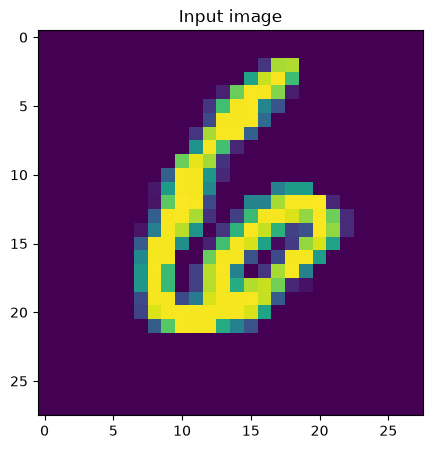

In [9]:
xi = x[13].reshape(28,28)
show_image(xi, (5,5), "Input image")

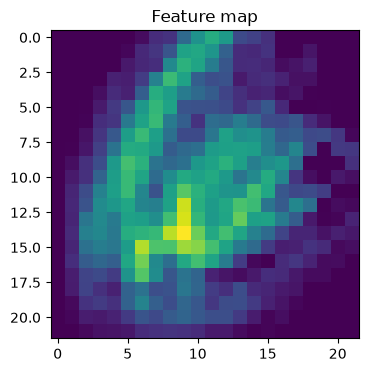

In [10]:
feat = feat_map(xi, w1, 1)
show_image(feat, (4,4), "Feature map")

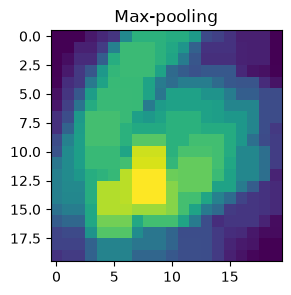

In [11]:
max_pool = pooling(feat, w2, 1, 'max')
show_image(max_pool, (3,3), "Max-pooling")

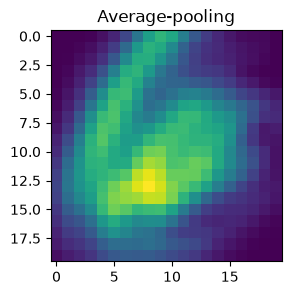

In [12]:
avg_pool = pooling(feat, w2, 1, 'avg')
show_image(avg_pool, (3,3), "Average-pooling")